In [1]:
# importing necessary libraries
import os
import subprocess
import shutil
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import multiprocessing as mp
from functools import partial
import time
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from scipy.interpolate import griddata

In [ ]:
# set the directory of the files
original_dir = os.getcwd()

data_dir =os.path.abspath("../Result_Files/AB") 

os.chdir(data_dir)
print(f"Current working directory: {os.getcwd()}")
sim_indentifier = "param_sweep_" + os.path.basename(data_dir)
print(f"Simulation identifier: {sim_indentifier}")

# Create a plot directory if it doesn't exist
plot_dir = os.path.join(original_dir, "Plots_Sensitivity", sim_indentifier)
print(f"plot directory: {plot_dir}")
os.makedirs(plot_dir, exist_ok=True) 

Current working directory: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm-dev/run/Result_Files_Final/AB
Simulation identifier: param_sweep_AB
plot directory: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm-dev/run/notebooks_post_processing/Plots_Sensitivity/param_sweep_AB


In [3]:

combined_data_file = os.path.join(data_dir, "combined_nurse_cell_activation.txt")
mean_summary_file = os.path.join(data_dir, "mean_summary.txt")
cv_summary_file = os.path.join(data_dir, "cv_summary.txt")
germ_summary_file = os.path.join(data_dir, "germ_cell_summary.txt")

# Read the mean and CV summary files into DataFrames
mean_summary_df = pd.read_csv(mean_summary_file, sep="\t")
cv_summary_df = pd.read_csv(cv_summary_file, sep="\t")
germ_summary_df = pd.read_csv(germ_summary_file, sep="\t")

# Read the data
# data = pd.read_csv(combined_data_file, sep="\t")

# # Get the first non-TimeStep column name
# first_param_col = next(col for col in data.columns if col != "TimeStep")

# # Extract shape from the first word before '_'
# shape = first_param_col.split('_')[0]

# Read only the first line of the file directly
with open(combined_data_file, "r") as f:
  header_columns = f.readline().strip().split("\t")

# Get the first non-TimeStep column name
first_param_col = next(col for col in header_columns if col != "TimeStep")

# Extract shape from the first word before '_'
shape = first_param_col.split('_')[0]

print(f"Shape extracted from the first parameter column: {shape}")

Shape extracted from the first parameter column: sphere


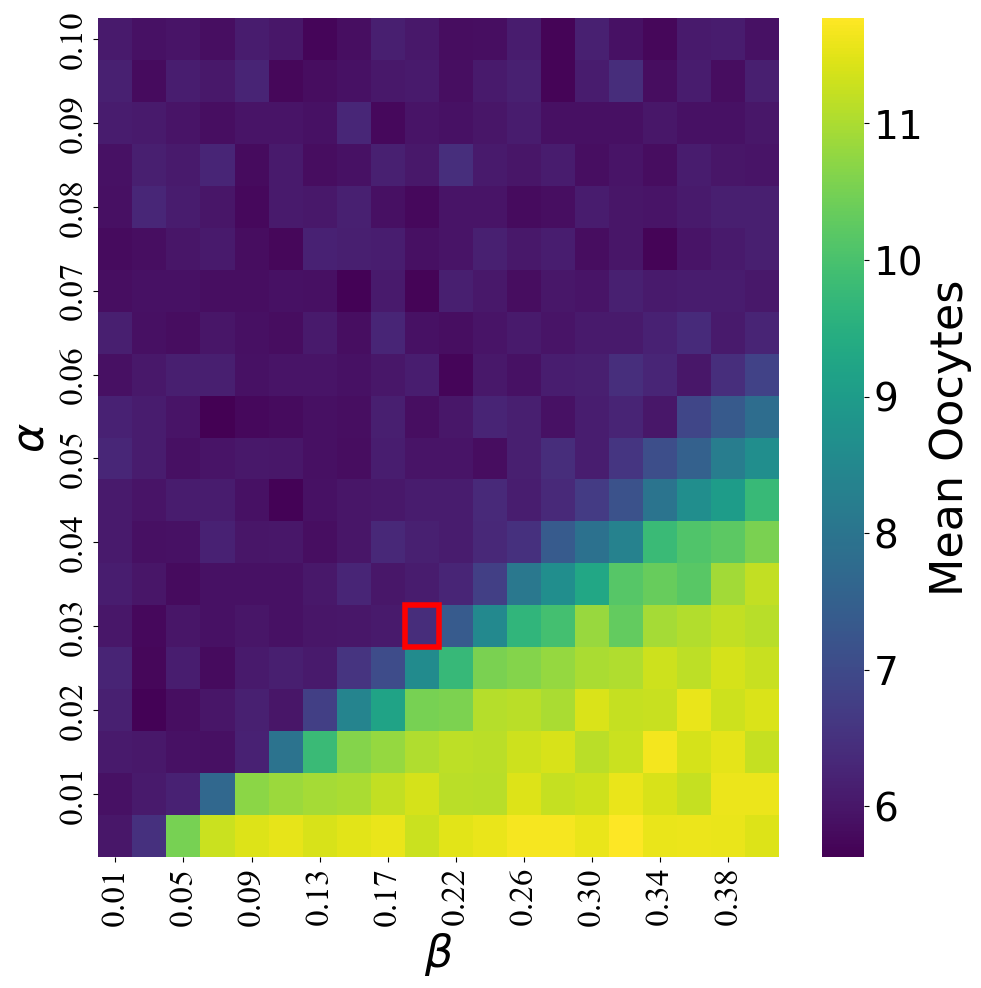

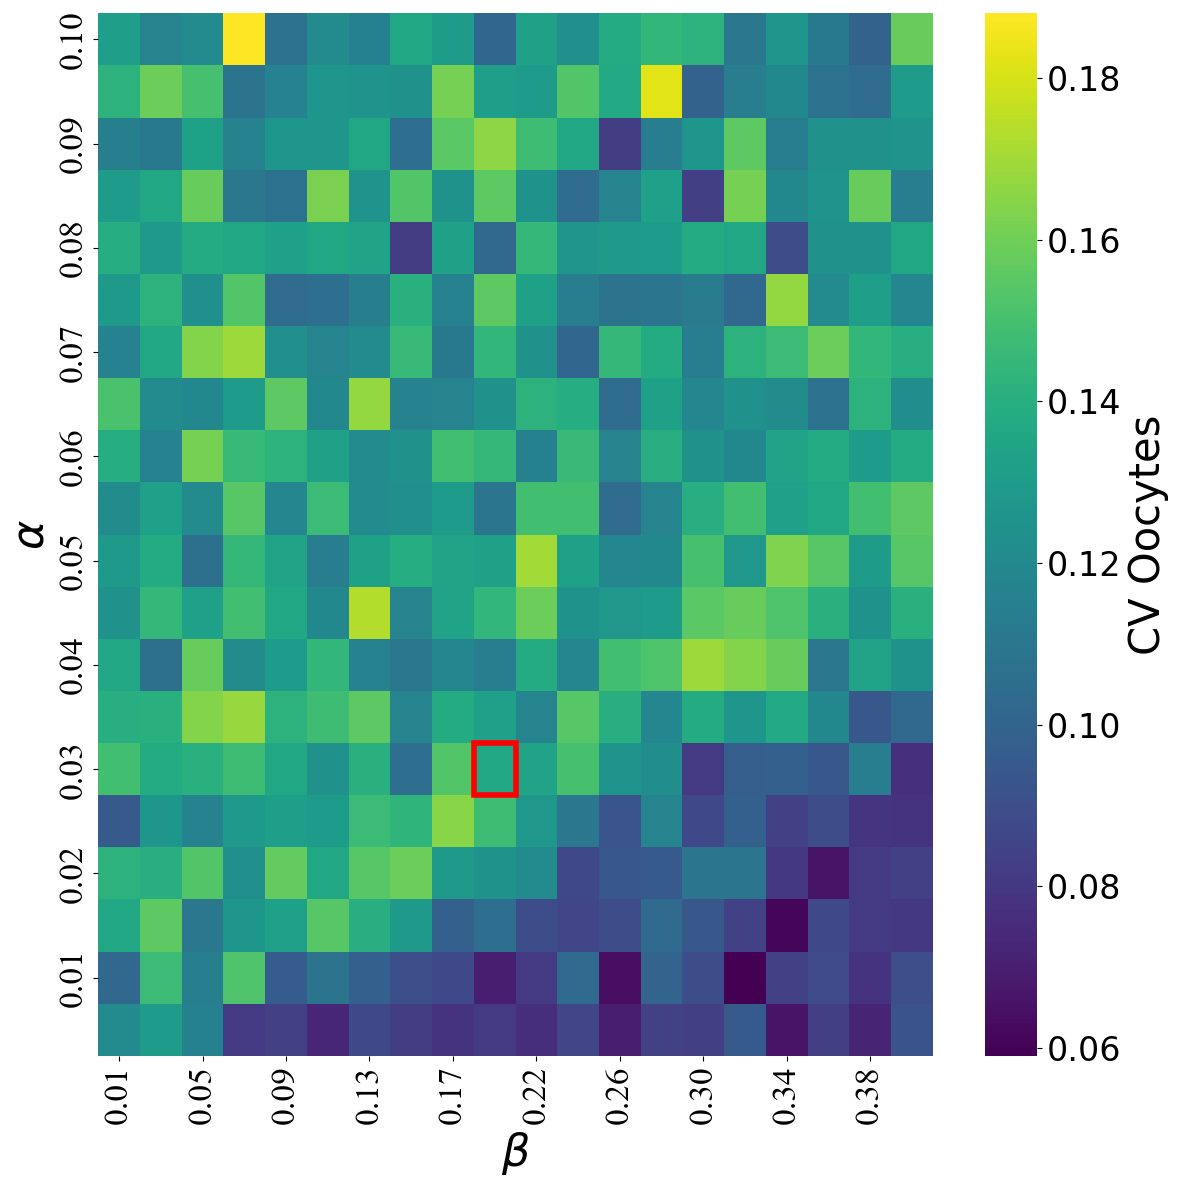

In [4]:


# Read the germ summary files into DataFrames
from matplotlib import axes
import matplotlib.patches as patches

# Specify exact baseline parameter values
baseline_alpha = 0.03  #  baseline alpha value
baseline_beta = 0.20 # bqseline beta value


germ_summary_df = pd.read_csv(germ_summary_file, sep="\t")
germ_summary_df.columns = germ_summary_df.columns.str.strip()

# Pivot the DataFrames to create matrix formats for the heatmaps
# mean_heatmap_data = mean_summary_df.pivot("External_Signal_Coeff", "PTN_threshold", "Mean_Last_NurseCellActivation")
# cv_heatmap_data = cv_summary_df.pivot("External_Signal_Coeff", "PTN_threshold", "CV_Last_NurseCellActivation")

mean_heatmap_data = germ_summary_df.pivot(index="alpha", columns="beta", values="Mean_Oocyte") # Panda 2.0 changes
cv_heatmap_data = germ_summary_df.pivot(index="alpha", columns="beta", values="CV_Oocyte")

mean_heatmap_data = mean_heatmap_data.iloc[::-1]  # Reverse the order of rows for better visualization
cv_heatmap_data = cv_heatmap_data.iloc[::-1]  # Reverse the order of rows for better visualization

# Locate matrix integer indices for the baseline parameter box
x_pos = np.argmin(np.abs(mean_heatmap_data.columns - baseline_beta))
y_pos = np.argmin(np.abs(mean_heatmap_data.index - baseline_alpha))

# Create a figure with two subplots for side-by-side heatmaps
fig, ax1 = plt.subplots(1, 1, figsize=(10, 10))

# Plot the mean heatmap with improved formatting
# sns.heatmap(mean_heatmap_data, annot=True, fmt=".2f", cmap="viridis", 
#             cbar_kws={'label': 'Mean Activation'}, ax=axes[0],
#             annot_kws={"size": 18, "weight": "bold"})  # Larger, bold annotations

sns.heatmap(mean_heatmap_data, fmt=".2f", cmap="viridis", 
            cbar_kws={'label': 'Mean Activation'}, ax=ax1)

ax1.add_patch(patches.Rectangle((x_pos, y_pos),1,1,fill=False,edgecolor="red",lw=4,clip_on=False,))

# Access the colorbar and set font sizes
cbar = ax1.collections[0].colorbar
cbar.ax.tick_params(labelsize=28)         # Set colorbar tick label size
cbar.set_label('Mean Oocytes', size=32)  # Set colorbar label font size
# ax1.set_title("Mean Total Pro-Oocytes", fontsize=34)
ax1.set_xlabel("$\\beta$", fontsize=32)  
ax1.set_ylabel("$\\alpha$", fontsize=32) 
ax1.tick_params(axis='both', which='major', labelsize=24)

# Show only alternate ticks
cols = mean_heatmap_data.columns.to_numpy()  # These are your Beta values
rows = mean_heatmap_data.index.to_numpy()    # These are your Alpha values (already reversed by iloc)

# Select every other tick (0, 2, 4...)
x_tick_indices = np.arange(0, len(cols), 2)
y_tick_indices = np.arange(0, len(rows), 2)

# Set positions
ax1.set_xticks([i + 0.5 for i in x_tick_indices])
ax1.set_yticks([i + 0.5 for i in y_tick_indices])

# Set labels 
ax1.set_xticklabels([f"{float(cols[i]):.2f}" for i in x_tick_indices], fontsize=24, family='Times New Roman')
ax1.set_yticklabels([f"{float(rows[i]):.2f}" for i in y_tick_indices], fontsize=24, family='Times New Roman')

# Adjust layout and display the plots
plt.tight_layout()
filename = "param_sensitivity_alpha_beta_mean.png"
plt.savefig(os.path.join(plot_dir, filename), dpi=300)
plt.show()

fig, ax2 = plt.subplots(1, 1, figsize=(12, 12))

sns.heatmap(cv_heatmap_data, fmt=".2f", cmap="viridis", 
            cbar_kws={'label': 'CV Activation'}, ax=ax2)

ax2.add_patch(patches.Rectangle((x_pos, y_pos),1,1,fill=False,edgecolor="red",lw=4,clip_on=False,))

# Access the colorbar and set font sizes
cbar = ax2.collections[0].colorbar
cbar.ax.tick_params(labelsize=24)         # Set colorbar tick label size
cbar.set_label('CV Oocytes', size=30)  # Set colorbar label font size
# ax2.set_title("CV of Total Pro-Oocytes", fontsize=32)
ax2.set_xlabel("$\\beta$", fontsize=32)  
ax2.set_ylabel("$\\alpha$", fontsize=32) 
ax2.tick_params(axis='both', which='major', labelsize=24)

# Show only alternate ticks
cols = cv_heatmap_data.columns.to_numpy()  # These are your Beta values
rows = cv_heatmap_data.index.to_numpy()    # These are your Alpha values (already reversed by iloc)

# Select every other tick (0, 2, 4...)
x_tick_indices = np.arange(0, len(cols), 2)
y_tick_indices = np.arange(0, len(rows), 2)

# Set positions
ax2.set_xticks([i + 0.5 for i in x_tick_indices])
ax2.set_yticks([i + 0.5 for i in y_tick_indices])

# Set labels 
ax2.set_xticklabels([f"{float(cols[i]):.2f}" for i in x_tick_indices], fontsize=24, family='Times New Roman')
ax2.set_yticklabels([f"{float(rows[i]):.2f}" for i in y_tick_indices], fontsize=24, family='Times New Roman')



# Adjust layout and display the plots
plt.tight_layout()
filename = "param_sensitivity_alpha_beta_cv.png"
plt.savefig(os.path.join(plot_dir, filename), dpi=300)
plt.show()

In [ ]:
os.chdir(original_dir) 